In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity

In [2]:
import pandas as pd

# Load dataset from Excel
df = pd.read_excel('Online Retail.xlsx')



In [3]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [5]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [6]:
df.shape

(541909, 8)

In [7]:
print(df.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


Data Cleaning

In [8]:
# Remove rows with missing CustomerID
df = df.dropna(subset=['CustomerID'])
print(df.shape)  # Check remaining rows

(406829, 8)


In [9]:
# Keep only positive Quantity and UnitPrice
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
print(df.shape)

(397884, 8)


In [10]:
df['CustomerID'] = df['CustomerID'].astype(int)

In [11]:
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


Feature Engineering (RFM Analysis)

In [12]:
# Convert InvoiceDate to datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Reference date (latest date in dataset)
reference_date = df['InvoiceDate'].max()

# RFM Calculation
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,  # Recency
    'InvoiceNo': 'count',                                     # Frequency
    'TotalPrice': 'sum'                                       # Monetary
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,325,1,77183.60
12347,1,182,4310.00
12348,74,31,1797.24
12349,18,73,1757.55
12350,309,17,334.40


Feature Scaling

In [14]:
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm)

📈 Find Optimal Clusters (Elbow Method)

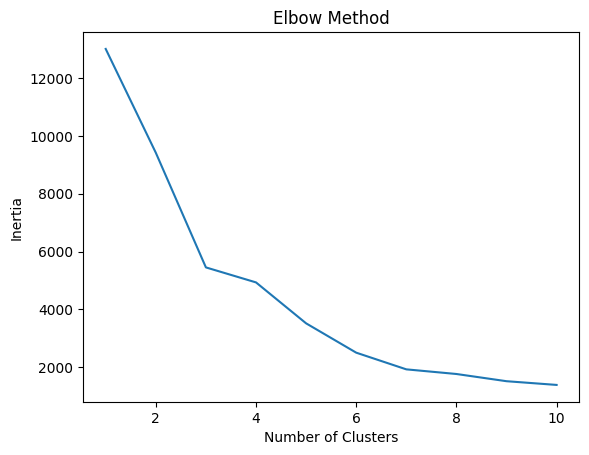

In [15]:
inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

plt.plot(range(1, 11), inertia)
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

Apply K-Means Clustering

In [16]:
kmeans = KMeans(n_clusters=4, random_state=42)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

rfm.head()

,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346,325,1,77183.60,3
12347,1,182,4310.00,0
12348,74,31,1797.24,1
12349,18,73,1757.55,0
12350,309,17,334.40,3


Cluster Analysis (Business Insight)

In [19]:
cluster_summary = rfm.groupby('Cluster').mean()
print(cluster_summary)

            Recency    Frequency       Monetary
Cluster                                        
0         19.990788   135.285122    2645.818172
1         97.218703    37.719457     773.877083
2          3.692308  2565.307692  126118.310000
3        271.407005    25.138889     605.842525


PCA Visualization

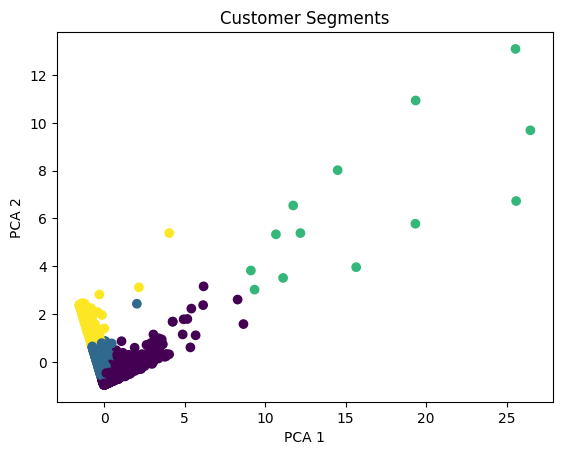

In [20]:
pca = PCA(n_components=2)
rfm_pca = pca.fit_transform(rfm_scaled)

plt.scatter(rfm_pca[:,0], rfm_pca[:,1], c=rfm['Cluster'])
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.title('Customer Segments')
plt.show()

Handle Outliers Properly

In [23]:
rfm_filtered = rfm[(rfm['Monetary'] < rfm['Monetary'].quantile(0.99)) &
                   (rfm['Frequency'] < rfm['Frequency'].quantile(0.99))].copy()

redo clustering:

In [24]:
rfm_filtered['Cluster'] = kmeans.fit_predict(rfm_scaled)

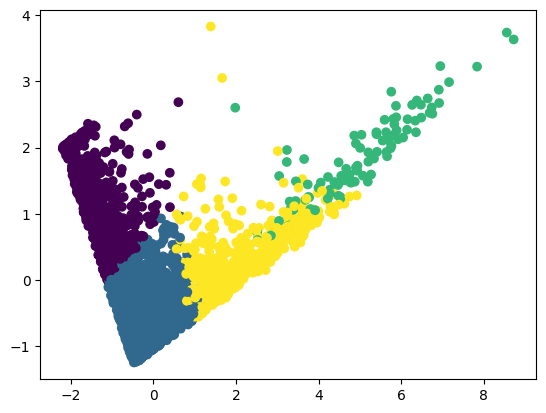

In [25]:
pca = PCA(n_components=2)
rfm_pca = pca.fit_transform(rfm_scaled)

plt.scatter(rfm_pca[:,0], rfm_pca[:,1], c=rfm_filtered['Cluster'])
plt.show()

In [26]:
from sklearn.metrics import silhouette_score

score = silhouette_score(rfm_scaled, rfm_filtered['Cluster'])
print("Silhouette Score:", score)

Silhouette Score: 0.5101557858695762


Rename Clusters

In [27]:
rfm_filtered['Segment'] = rfm_filtered['Cluster'].map({
    0: 'Low Engagement',
    1: 'Regular Customers',
    2: 'High Value Customers',
    3: 'At Risk Customers'
})

In [37]:
segment_counts = rfm_filtered['Segment'].value_counts()
print(segment_counts)

Segment
Regular Customers       2529
Low Engagement          1030
At Risk Customers        605
High Value Customers     100
Name: count, dtype: int64


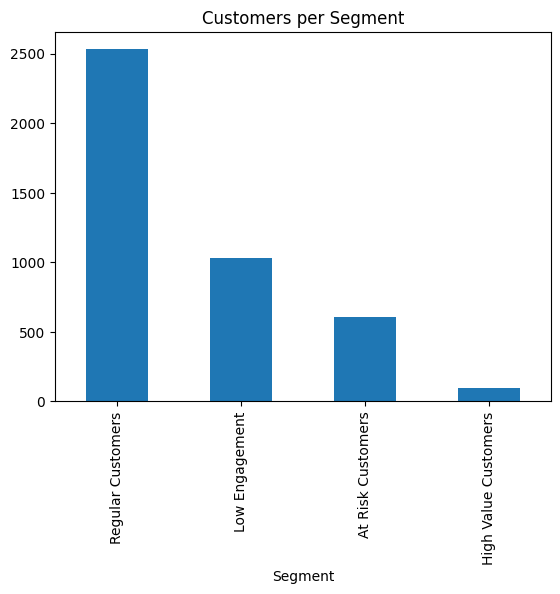

In [38]:
segment_counts.plot(kind='bar')
plt.title("Customers per Segment")
plt.show()

# Customer Similarity (RFM-based)

In [39]:
from sklearn.metrics.pairwise import cosine_similarity

# Use scaled features (important)
similarity_matrix = cosine_similarity(rfm_scaled)

# Convert to DataFrame
similarity_df = pd.DataFrame(
    similarity_matrix,
    index=rfm_filtered.index,
    columns=rfm_filtered.index
)

In [40]:
similarity_df.head()

CustomerID,12347,12348,12349,12350,12352,12353,12354,12355,12356,12357,...,18272,18273,18274,18276,18277,18278,18280,18281,18282,18287
CustomerID,,,,,,,,,,,,,,,,,,,,,
12347,1.000000,-0.039125,0.587993,-0.724750,0.873579,-0.916023,-0.590302,-0.843898,0.712674,0.901068,...,0.974829,-0.306319,-0.450796,-0.505971,-0.657230,-0.755826,-0.789228,-0.951271,-0.316320,0.636181
12348,-0.039125,1.000000,0.462663,-0.177547,0.410804,0.017158,-0.262366,-0.013906,0.655385,0.248272,...,-0.110270,0.566595,0.524002,0.552955,0.491415,0.474037,-0.129411,0.058636,0.521323,0.564559
12349,0.587993,0.462663,1.000000,-0.951395,0.857044,-0.806769,-0.974052,-0.864577,0.852650,0.455682,...,0.674494,0.589681,0.456347,0.400006,0.223040,0.082438,-0.925290,-0.747809,0.579014,0.982305
12350,-0.724750,-0.177547,-0.951395,1.000000,-0.853975,0.931185,0.983043,0.972677,-0.760376,-0.495884,...,-0.830323,-0.400841,-0.260845,-0.188828,-0.009144,0.140213,0.994786,0.887264,-0.401896,-0.909580
12352,0.873579,0.410804,0.857044,-0.853975,1.000000,-0.887213,-0.791115,-0.863053,0.957832,0.849120,...,0.860860,0.131416,-0.023863,-0.071337,-0.250303,-0.367853,-0.877271,-0.881859,0.107620,0.916085


In [42]:
def recommend_customers(customer_id, top_n=5):
    similar_scores = similarity_df[customer_id].sort_values(ascending=False)
    return similar_scores.iloc[1:top_n+1]

In [44]:
recommend_customers(12347)

,12347
CustomerID,
14107,0.999935
15514,0.999643
16626,0.999636
12668,0.999293
14401,0.999106


Product Recommendation System

In [45]:
basket = df.pivot_table(
    index='CustomerID',
    columns='StockCode',
    values='Quantity',
    aggfunc='sum',
    fill_value=0
)

Convert to binary (purchased or not)

In [48]:
basket = basket.map(lambda x: 1 if x > 0 else 0)

Compute product similarity

In [50]:
item_similarity = cosine_similarity(basket.T)

item_similarity_df = pd.DataFrame(
    item_similarity,
    index=basket.columns,
    columns=basket.columns
)

Product recommendation function

In [51]:
def recommend_products(product_code, top_n=5):
    similar_products = item_similarity_df[product_code].sort_values(ascending=False)
    return similar_products.iloc[1:top_n+1]

In [55]:
recommend_products(basket.columns[100])

,20725
StockCode,
20728,0.610137
20727,0.607761
22384,0.606980
22382,0.591498
22383,0.588960


Combine with Segmentation

In [56]:
def smart_recommend(customer_id):
    segment = rfm_filtered.loc[customer_id, 'Segment']

    if segment == 'High Value Customers':
        return "Recommend premium/high-value products"

    elif segment == 'At Risk Customers':
        return "Recommend discounts and offers"

    else:
        return "Recommend popular products"

In [61]:
smart_recommend(13384)

'Recommend discounts and offers'

# Final Business Output

1. Identified similar customers for personalized marketing
2. Recommended products based on purchase behavior
3. Integrated customer segmentation with recommendation logic
4. Enabled targeted marketing and cross-selling

In [62]:
rfm_filtered.to_csv('rfm_segments.csv')
similarity_df.to_csv('customer_similarity.csv')
item_similarity_df.to_csv('item_similarity.csv')